# Búsqueda de la Mejor Arquitectura MLP
**Proyecto Integrador · Aprendizaje Profundo**  
Estación A001 — Brasília, DF · 2020–2026

---

## 1. Introducción

La selección de la arquitectura de una red neuronal es uno de los factores más críticos en el rendimiento de un modelo de aprendizaje profundo. Para un perceptrón multicapa (MLP) de predicción multi-step, los hiperparámetros de mayor impacto son: (a) el **número de capas ocultas**, (b) el **número de neuronas por capa** y (c) la **configuración de dropout** por capa.

Este cuaderno implementa una **búsqueda exhaustiva (grid search)** sobre el espacio combinatorio de arquitecturas y máscaras de dropout, siguiendo la metodología descrita en el guión de la asignatura. La evaluación de cada candidato se realiza con **validación temporal sin mezcla** (Forward Chaining), respetando la causalidad de la serie.

El criterio de selección final combina:
- **Mínimo RMSE de validación** (`best_val_rmse`), y
- **Bajo sobreajuste**: `gap_ratio = |RMSE_train − RMSE_val| / RMSE_val < 0.15`.

La búsqueda exhaustiva (584 candidatos) se ejecuta sobre la configuración representativa **lag = 14 días, H = 7 días**. Después, los 10 mejores candidatos se reentrenan en cada una de las 16 combinaciones lag × horizonte y en cada una se elige la mejor arquitectura con el mismo criterio. El enunciado admite este alcance siempre que se justifique (sección 9).

---

## 2. Importar librerías y configurar entorno

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import gc
import math
import time
import itertools
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

from tsxv.splitTrainVal import split_train_val_forwardChaining

tf.get_logger().setLevel('ERROR')
tf.keras.utils.set_random_seed(42)

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.prop_cycle': matplotlib.cycler('color', ['#000000', '#444444', '#888888', '#bbbbbb']),
    'axes.grid': True, 'grid.alpha': 0.3,
    'font.size': 10, 'axes.titlesize': 11,
})

BASE_DIR    = os.path.dirname(os.getcwd())
DATA_PATH   = os.path.join(BASE_DIR, 'data', 'dataset.csv')
RESULTS_DIR = os.path.join(BASE_DIR, 'results')
FIGS_DIR    = os.path.join(os.getcwd(), 'figs')
LOG_PATH    = os.path.join(RESULTS_DIR, 'progreso_busqueda.log')
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGS_DIR, exist_ok=True)

print(f'TensorFlow: {tf.__version__}')
print(f'Dataset: {os.path.relpath(DATA_PATH, BASE_DIR)}')

TensorFlow: 2.21.0
Dataset: data\dataset.csv


## 3. Cargar datos y definir hold-out temporal

El **hold-out temporal** reserva el último 10 % de la serie (mínimo 2·max(horizonte) días) para la evaluación definitiva del modelo final. Este segmento **no participa** en ninguna etapa de validación cruzada, búsqueda de arquitectura ni ajuste de escaladores, garantizando una estimación de generalización libre de *data leakage*.

Los modelos usan la serie de 2020 a 2026 (2 496 días), mientras el EDA del cuaderno 1 analiza la serie completa (2000–2026). La búsqueda de arquitecturas y la validación cruzada suman más de 1 000 entrenamientos (734 en este cuaderno, 240 en el cuaderno 3 y 80 en el 5), de modo que acotar la muestra a los siete años más recientes mantiene el costo en unas dos horas de CPU y centra el modelo en el periodo más cercano a su uso.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['date'])
df = df.sort_values('date').reset_index(drop=True)

# Últimos 7 años (2020-2026). El EDA (cuaderno 1) usa la serie completa;
# aquí se reduce la muestra para que la búsqueda corra en tiempo razonable.
df = df[df.date >= '2020-01-01'].reset_index(drop=True)

y_full = df['wind_speed'].values.astype(np.float32)

# ---- Parámetros globales ----
LAGS_LIST     = [7, 14, 21, 28]
HORIZONS_LIST = [7, 14, 21, 28]
N_STEPS_JUMP  = 7
HOLDOUT_FRAC  = 0.10
EPOCHS_SEARCH = 30
BATCH_SIZE    = 32
DROPOUT_RATE  = 0.5
GAP_UMBRAL    = 0.15
TOP_K_REEVAL  = 10
LAG_DEMO, HORIZON_DEMO = 14, 7

n_hold = max(int(len(y_full) * HOLDOUT_FRAC), 2 * max(HORIZONS_LIST))
serie_cv      = y_full[:-n_hold]
serie_holdout = y_full[-n_hold:]

print(f'Rango temporal        : {df.date.min().date()} a {df.date.max().date()}')
print(f'Observaciones totales : {len(y_full)}')
print(f'Serie CV              : {len(serie_cv)} (hasta {df.date.iloc[len(serie_cv) - 1].date()})')
print(f'Hold-out              : {len(serie_holdout)} ({n_hold / len(y_full) * 100:.1f} %, desde {df.date.iloc[len(serie_cv)].date()})')

Rango temporal        : 2020-01-01 a 2026-10-31
Observaciones totales : 2496
Serie CV              : 2247 (hasta 2026-02-24)
Hold-out              : 249 (10.0 %, desde 2026-02-25)


### 3.1 Partición temporal para la búsqueda

En la versión instalada de `timeseries-cv` (0.1.5), `split_train_val_forwardChaining` crea un fold por origen: con `numJumps = 7` y lag = 14 se obtienen unos 315 folds, cada uno con **una sola ventana de validación**, y el fold 0 entrena con apenas 2 ventanas. Una búsqueda sobre un único fold de ese tipo no distingue arquitecturas.

Por eso la búsqueda toma como entrenamiento el fold de Forward Chaining situado en el 80 % de los orígenes (≈ 255 ventanas) y valida con las ventanas de los folds posteriores. Entre ambos tramos se descartan ⌈H / `numJumps`⌉ orígenes (purga), de modo que ningún objetivo de validación coincide con un objetivo de entrenamiento. Los escaladores se ajustan solo con el tramo de entrenamiento, y con ellos se transforman la validación y el hold-out. Las métricas de la búsqueda (`best_val_rmse`, `last_train_rmse`, `holdout_rmse`) quedan en escala estandarizada.

In [3]:
def particion_busqueda(serie, lag, H, jump=N_STEPS_JUMP, frac_train=0.8):
    X, y, Xcv, ycv = split_train_val_forwardChaining(
        serie, numInputs=lag, numOutputs=H, numJumps=jump)
    folds = sorted(X)
    origen = folds[int(len(folds) * frac_train)]
    purga = math.ceil(H / jump)
    folds_val = [f for f in folds if f >= origen + purga]
    X_val = np.vstack([Xcv[f] for f in folds_val])
    y_val = np.vstack([ycv[f] for f in folds_val])
    return X[origen], y[origen], X_val, y_val, len(folds)


def ventanas_holdout(serie_cv, serie_holdout, lag, H):
    """Ventanas con paso 1 cuyos objetivos caen por completo en el hold-out."""
    base = np.concatenate([serie_cv[-lag:], serie_holdout])
    n = len(base) - lag - H + 1
    X = np.array([base[i:i + lag] for i in range(n)], dtype=np.float32)
    y = np.array([base[i + lag:i + lag + H] for i in range(n)], dtype=np.float32)
    return X, y


def preparar(lag, H):
    Xtr, ytr, Xvl, yvl, n_folds = particion_busqueda(serie_cv, lag, H)
    Xho, yho = ventanas_holdout(serie_cv, serie_holdout, lag, H)
    sx = StandardScaler().fit(Xtr)
    sy = StandardScaler().fit(ytr)
    datos = dict(
        X_train=sx.transform(Xtr), y_train=sy.transform(ytr),
        X_val=sx.transform(Xvl),   y_val=sy.transform(yvl),
        X_hold=sx.transform(Xho),  y_hold=sy.transform(yho),
    )
    return datos, n_folds


datos_demo, n_folds_demo = preparar(LAG_DEMO, HORIZON_DEMO)
print(f'Folds de Forward Chaining (tsxv) para lag={LAG_DEMO}, H={HORIZON_DEMO}: {n_folds_demo}')
for nombre in ['train', 'val', 'hold']:
    print(f'  {nombre:5s}: X={datos_demo["X_" + nombre].shape}, y={datos_demo["y_" + nombre].shape}')

Folds de Forward Chaining (tsxv) para lag=14, H=7: 316
  train: X=(254, 14), y=(254, 7)
  val  : X=(63, 14), y=(63, 7)
  hold : X=(243, 14), y=(243, 7)


## 4. Espacio de búsqueda

El espacio de búsqueda se define como el producto cartesiano de:

| Componente | Opciones |
|---|---|
| Neuronas por capa | 32, 64, 128, 256 |
| Número de capas | 1, 2, 3 (mínimo recomendado: 3) |
| Máscara de dropout | Todas las combinaciones booleanas $2^n$ para $n$ capas |

Para $n=3$ capas: $4^3=64$ arquitecturas × $2^3=8$ máscaras = **512 candidatos** por configuración (lag, horizonte). Por costo computacional, se usa `max_capas=3`; se recomienda subir a 4 si el hardware lo permite.

In [4]:
NEURONAS  = [32, 64, 128, 256]
MAX_CAPAS = 3

arquitecturas = []
for num_capas in range(1, MAX_CAPAS + 1):
    for comb in itertools.product(NEURONAS, repeat=num_capas):
        arquitecturas.append(comb)


def dropout_configs(n_capas):
    """Genera las 2^n máscaras booleanas de dropout para n capas."""
    for mask in range(2 ** n_capas):
        yield tuple(bool((mask >> i) & 1) for i in range(n_capas))


CANDIDATOS = [(a, dm) for a in arquitecturas for dm in dropout_configs(len(a))]
print(f'Arquitecturas (sin dropout): {len(arquitecturas)}')
print(f'Candidatos (arquitectura × máscara de dropout): {len(CANDIDATOS)}')
for a, dm in CANDIDATOS[:6]:
    print(f'  Arch={a}  Dropout={dm}')

Arquitecturas (sin dropout): 84
Candidatos (arquitectura × máscara de dropout): 584
  Arch=(32,)  Dropout=(False,)
  Arch=(32,)  Dropout=(True,)
  Arch=(64,)  Dropout=(False,)
  Arch=(64,)  Dropout=(True,)
  Arch=(128,)  Dropout=(False,)
  Arch=(128,)  Dropout=(True,)


## 5. Funciones auxiliares

### 5.1 Construcción del modelo Keras multi-salida

El modelo sigue la arquitectura:

$$\text{Input}(n_{\text{input}}) \rightarrow [\text{Dense}(u_k, \text{ReLU}) + \text{Dropout}_{0.5}] \times L \rightarrow \text{Dense}(H)$$

donde $H \in \{7, 14, 21, 28\}$ es el horizonte de predicción y $L$ el número de capas ocultas. La salida lineal de tamaño $H$ permite predicciones simultáneas en todos los pasos del horizonte.

In [5]:
def registrar(msg):
    linea = f'[{time.strftime("%H:%M:%S")}] {msg}'
    print(linea, flush=True)
    with open(LOG_PATH, 'a', encoding='utf-8') as f:
        f.write(linea + '\n')


def construir_modelo(arquitectura, dropout_mask, input_dim, n_outputs, dropout_rate=DROPOUT_RATE):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(input_dim,)))
    for idx, units in enumerate(arquitectura):
        model.add(tf.keras.layers.Dense(units, activation='relu'))
        if dropout_mask[idx]:
            model.add(tf.keras.layers.Dropout(dropout_rate))
    model.add(tf.keras.layers.Dense(n_outputs))
    model.compile(optimizer='adam', loss='mse',
                  metrics=[tf.keras.metrics.RootMeanSquaredError()])
    return model


def evaluar_candidato(arch, dmask, datos, epochs=EPOCHS_SEARCH, batch_size=BATCH_SIZE):
    """Entrena un candidato sin shuffle y registra las métricas que pide el enunciado.

    ReduceLROnPlateau reduce el learning rate antes de que EarlyStopping detenga
    el entrenamiento; start_from_epoch evita
    detenciones en las primeras épocas, de alta varianza (Prechelt, 1998).
    """
    tf.keras.backend.clear_session()
    model = construir_modelo(arch, dmask, datos['X_train'].shape[1], datos['y_train'].shape[1])
    callbacks = [
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_root_mean_squared_error', factor=0.5, patience=2, min_lr=1e-6),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_root_mean_squared_error', patience=5, min_delta=0.001,
            restore_best_weights=True, start_from_epoch=3),
    ]
    history = model.fit(
        datos['X_train'], datos['y_train'],
        validation_data=(datos['X_val'], datos['y_val']),
        epochs=epochs, batch_size=batch_size, shuffle=False, verbose=0,
        callbacks=callbacks,
    )
    train_curve = history.history['root_mean_squared_error']
    val_curve   = history.history['val_root_mean_squared_error']
    best_val    = float(np.min(val_curve))
    last_train  = float(train_curve[-1])
    y_pred_hold = model(datos['X_hold'], training=False).numpy()
    return {
        'arquitectura'   : arch,
        'dropout_mask'   : dmask,
        'n_capas'        : len(arch),
        'neuronas_total' : int(sum(arch)),
        'n_dropout'      : int(sum(dmask)),
        'best_val_rmse'  : best_val,
        'last_train_rmse': last_train,
        'gap'            : abs(last_train - best_val),
        'holdout_rmse'   : float(np.sqrt(mean_squared_error(datos['y_hold'], y_pred_hold))),
        'epocas_usadas'  : len(train_curve),
        'train_curve'    : train_curve,
        'val_curve'      : val_curve,
    }


def buscar_mejor_arquitectura(datos, candidatos, etiqueta):
    resultados, t0, n = [], time.time(), len(candidatos)
    for i, (arch, dmask) in enumerate(candidatos, 1):
        resultados.append(evaluar_candidato(arch, dmask, datos))
        if i % 50 == 0 or i == n:
            transcurrido = time.time() - t0
            faltan = transcurrido / i * (n - i)
            registrar(f'{etiqueta}: {i}/{n} candidatos | {transcurrido / 60:.1f} min | faltan ~{faltan / 60:.1f} min')
    gc.collect()
    df_res = pd.DataFrame(resultados)
    df_res['gap_ratio']   = df_res['gap'] / df_res['best_val_rmse']
    df_res['balanceado'] = df_res['gap_ratio'] < GAP_UMBRAL
    return df_res


def ranking(df_res):
    """Balanceados (gap_ratio < 0,15) por best_val_rmse; si faltan, los menos sobreajustados."""
    bal   = df_res[df_res.balanceado].sort_values('best_val_rmse')
    resto = df_res[~df_res.balanceado].sort_values('gap_ratio')
    return pd.concat([bal, resto]).reset_index(drop=True)


COLS_TABLA = ['arquitectura', 'dropout_mask', 'best_val_rmse', 'last_train_rmse',
              'gap', 'gap_ratio', 'holdout_rmse', 'epocas_usadas', 'balanceado']


def guardar_tabla(rank, lag, H):
    tabla = rank[COLS_TABLA].copy()
    tabla['arquitectura'] = tabla['arquitectura'].apply(str)
    tabla['dropout_mask'] = tabla['dropout_mask'].apply(str)
    tabla.to_csv(os.path.join(RESULTS_DIR, f'architecture_search_lag{lag}_h{H}.csv'), index=False)

## 6. Búsqueda exhaustiva en la configuración representativa (lag = 14, H = 7)

Se entrenan los 584 candidatos con la partición de la sección 3.1. El avance queda registrado en `results/progreso_busqueda.log`. La tabla completa se guarda en `results/architecture_search_lag14_h7.csv`.

In [6]:
if os.path.exists(LOG_PATH):
    os.remove(LOG_PATH)
registrar(f'Inicio: búsqueda exhaustiva lag={LAG_DEMO}, H={HORIZON_DEMO} con {len(CANDIDATOS)} candidatos')

df_res_demo = buscar_mejor_arquitectura(datos_demo, CANDIDATOS, f'lag={LAG_DEMO} H={HORIZON_DEMO}')
rank_demo = ranking(df_res_demo)
guardar_tabla(rank_demo, LAG_DEMO, HORIZON_DEMO)

print(f'Candidatos balanceados (gap_ratio < {GAP_UMBRAL}): {int(df_res_demo.balanceado.sum())} de {len(df_res_demo)}')
print(f'Épocas usadas: media {df_res_demo.epocas_usadas.mean():.1f} de {EPOCHS_SEARCH}')

[17:49:14] Inicio: búsqueda exhaustiva lag=14, H=7 con 584 candidatos


[17:52:42] lag=14 H=7: 50/584 candidatos | 3.5 min | faltan ~37.0 min


[17:56:04] lag=14 H=7: 100/584 candidatos | 6.8 min | faltan ~33.0 min


[17:59:40] lag=14 H=7: 150/584 candidatos | 10.4 min | faltan ~30.2 min


[18:03:11] lag=14 H=7: 200/584 candidatos | 13.9 min | faltan ~26.8 min


[18:07:14] lag=14 H=7: 250/584 candidatos | 18.0 min | faltan ~24.0 min


... (4 outputs left out)

[18:29:20] lag=14 H=7: 500/584 candidatos | 40.1 min | faltan ~6.7 min


[18:33:59] lag=14 H=7: 550/584 candidatos | 44.7 min | faltan ~2.8 min


[18:37:17] lag=14 H=7: 584/584 candidatos | 48.0 min | faltan ~0.0 min


Candidatos balanceados (gap_ratio < 0.15): 563 de 584
Épocas usadas: media 20.5 de 30


## 7. Tabla Top-5 de arquitecturas candidatas

La tabla reporta, para cada candidato: arquitectura (neuronas por capa), máscara de dropout, RMSE mínimo de validación, RMSE en train al final del entrenamiento, brecha (*gap*), ratio de sobreajuste y RMSE en hold-out (solo como evidencia final, no usado para selección).

In [7]:
top5 = rank_demo[COLS_TABLA].head(5).copy()
top5['arquitectura'] = top5['arquitectura'].apply(str)
top5['dropout_mask'] = top5['dropout_mask'].apply(str)
print(f'Top-5 arquitecturas (lag={LAG_DEMO}, H={HORIZON_DEMO}) — métricas de validación en escala estandarizada')
display(top5.round(4))

Top-5 arquitecturas (lag=14, H=7) — métricas de validación en escala estandarizada


,arquitectura,dropout_mask,best_val_rmse,last_train_rmse,gap,gap_ratio,holdout_rmse,epocas_usadas,balanceado
0,"(64, 256, 128)","(False, True, True)",0.9504,0.9049,0.0456,0.0479,0.9602,28,True
1,"(256, 64, 256)","(False, False, True)",0.9516,0.8386,0.1130,0.1188,0.9571,13,True
2,"(256, 32, 64)","(True, False, True)",0.9522,0.9419,0.0103,0.0108,0.9555,30,True
3,"(256, 32, 128)","(False, True, True)",0.9531,0.9282,0.0249,0.0261,0.9582,25,True
4,"(256, 128, 64)","(True, False, True)",0.9534,0.9333,0.0201,0.0211,0.9574,27,True


**Interpretación.** Los cinco mejores candidatos para lag = 14 y H = 7 tienen tres capas ocultas, usan dropout al menos en la última capa y quedan en una franja muy estrecha de `best_val_rmse`, entre 0,9504 y 0,9534 en escala estandarizada. El primero, (64, 256, 128) con dropout en las capas 2 y 3, combina el menor error de validación con un `gap_ratio` de 0,048, y su `holdout_rmse` de 0,9602 apenas supera en 1 % al de validación, de modo que el desempeño se sostiene en el tramo final de la serie, que nunca participó en la búsqueda.

Esto significa que las cifras deben leerse en su escala: como los objetivos se estandarizan con la media y la desviación del entrenamiento, un RMSE de 1 equivale en la práctica a predecir siempre la media, y el mejor candidato reduce ese error en cerca de un 5 %. Igual, la distancia entre el primero y el quinto puesto (0,003) es muy pequeña frente al rango de los 584 candidatos, que va de 0,9504 a 1,0201, por lo que entre los primeros lugares las arquitecturas son prácticamente equivalentes y el orden fino depende de una sola partición.

Por tal motivo, se opta por aplicar el criterio del enunciado sin modificarlo, filtro `gap_ratio < 0,15` y menor `best_val_rmse`, y por confirmar la elección con la validación cruzada de cinco folds del cuaderno 3, que es una evidencia más estable que una única partición.

## 8. Curvas de aprendizaje del Top-3

Las curvas de aprendizaje muestran la evolución del RMSE en train y validación a lo largo de las épocas para las tres mejores arquitecturas candidatas. Un buen modelo muestra convergencia paralela de ambas curvas sin divergencia creciente (sobreajuste) ni estancamiento prematuro (subajuste).

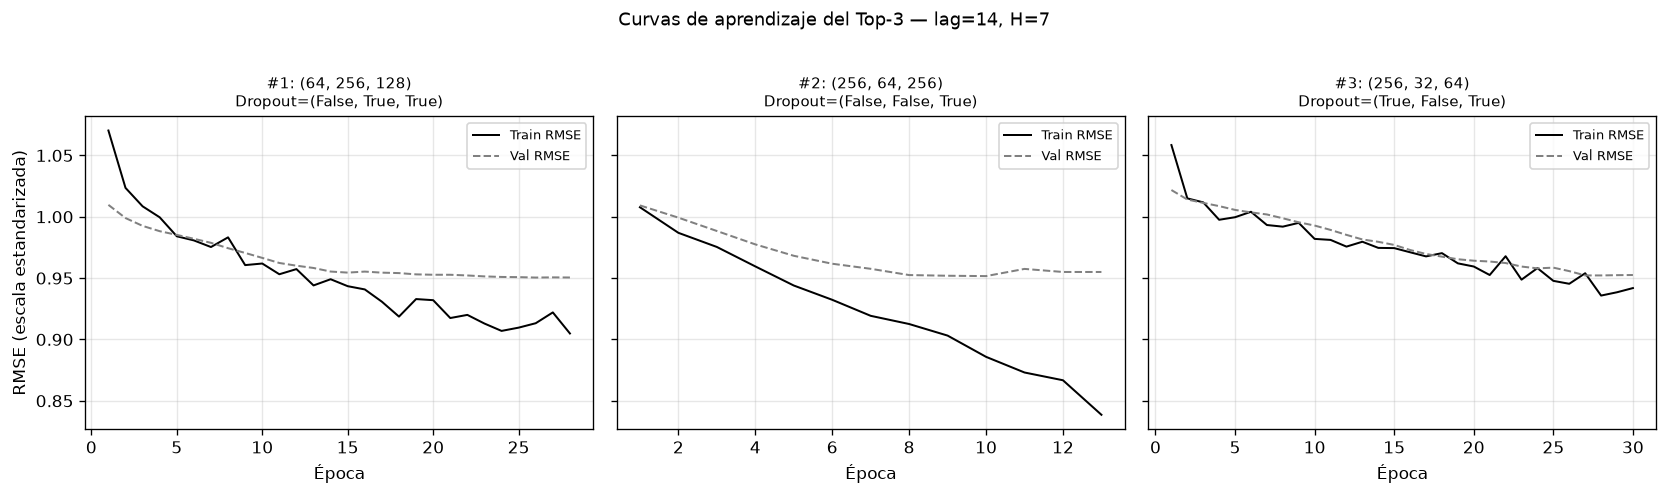

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for i, (_, row) in enumerate(rank_demo.head(3).iterrows()):
    ax = axes[i]
    ax.plot(range(1, len(row['train_curve']) + 1), row['train_curve'], lw=1.2, ls='-',  color='black', label='Train RMSE')
    ax.plot(range(1, len(row['val_curve']) + 1),   row['val_curve'],   lw=1.2, ls='--', color='gray',  label='Val RMSE')
    ax.set_title(f'#{i + 1}: {row["arquitectura"]}\nDropout={row["dropout_mask"]}', fontsize=9)
    ax.set_xlabel('Época')
    if i == 0:
        ax.set_ylabel('RMSE (escala estandarizada)')
    ax.legend(fontsize=8)
plt.suptitle(f'Curvas de aprendizaje del Top-3 — lag={LAG_DEMO}, H={HORIZON_DEMO}', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, f'arq_learning_curves_lag{LAG_DEMO}_h{HORIZON_DEMO}.png'), dpi=150, bbox_inches='tight')
plt.show()

**Interpretación.** En los tres primeros candidatos el RMSE de validación baja rápido en las primeras épocas y luego se estabiliza. El candidato 2, (256, 64, 256) sin dropout en las dos primeras capas, se detiene por EarlyStopping en la época 13 con la mayor brecha del grupo: RMSE de entrenamiento de 0,839 frente a 0,952 en validación (`gap_ratio` = 0,119). Los candidatos 1 y 3, en cambio, llegan a 28 y 30 épocas con brechas de 0,048 y 0,011.

Hay que tener en cuenta que Keras calcula el RMSE de entrenamiento con el dropout activo, de manera que en las redes con más dropout la curva de entrenamiento queda por encima de lo que daría el modelo en inferencia y la brecha se ve menor de lo que es. Aun así, el contraste entre el candidato 2 y los otros dos confirma que retirar el dropout de las primeras capas acelera el ajuste al entrenamiento y abre la brecha, y que los candidatos 1 y 3 agoten casi las 30 épocas indica que con más iteraciones todavía podían mejorar.

En consecuencia, se decide mantener 30 épocas con EarlyStopping en la búsqueda, donde lo importante es ordenar candidatos a un costo razonable, y ampliar a 100 épocas con paciencia de 20 en el entrenamiento del cuaderno 3, para no cortar a las arquitecturas que aún convergen (Prechelt, 1998).

## 8.1 Efecto del número de capas, del ancho y del dropout

El enunciado pide analizar cómo influyen la profundidad, el ancho de las capas y el dropout en el error de validación y en la brecha train–val. Las tablas y la figura resumen los 584 candidatos de la búsqueda exhaustiva.

=== Capas ocultas ===


,candidatos,val_rmse_media,val_rmse_min,gap_ratio_media,balanceados
n_capas,,,,,
1,8,0.9928,0.9704,0.0601,8
2,64,0.9814,0.9557,0.0606,62
3,512,0.9806,0.9504,0.0524,493


=== Neuronas totales ===


,candidatos,val_rmse_media,val_rmse_min,gap_ratio_media,balanceados
neuronas_total,,,,,
32,2,1.0093,1.0034,0.0365,2
64,6,0.9984,0.9827,0.0423,6
96,16,0.9959,0.9723,0.0341,16
128,30,0.9931,0.9583,0.0396,30
160,32,0.9931,0.9712,0.0428,32
192,40,0.9878,0.9616,0.0449,39
224,48,0.9875,0.9598,0.0440,48
256,30,0.9802,0.9627,0.0506,30
288,32,0.9874,0.9557,0.0504,31


=== Capas con dropout ===


,candidatos,val_rmse_media,val_rmse_min,gap_ratio_media,balanceados
n_dropout,,,,,
0,84,0.9806,0.9578,0.1342,64
1,228,0.9750,0.9516,0.0631,227
2,208,0.9815,0.9504,0.0236,208
3,64,1.0002,0.9539,0.0100,64


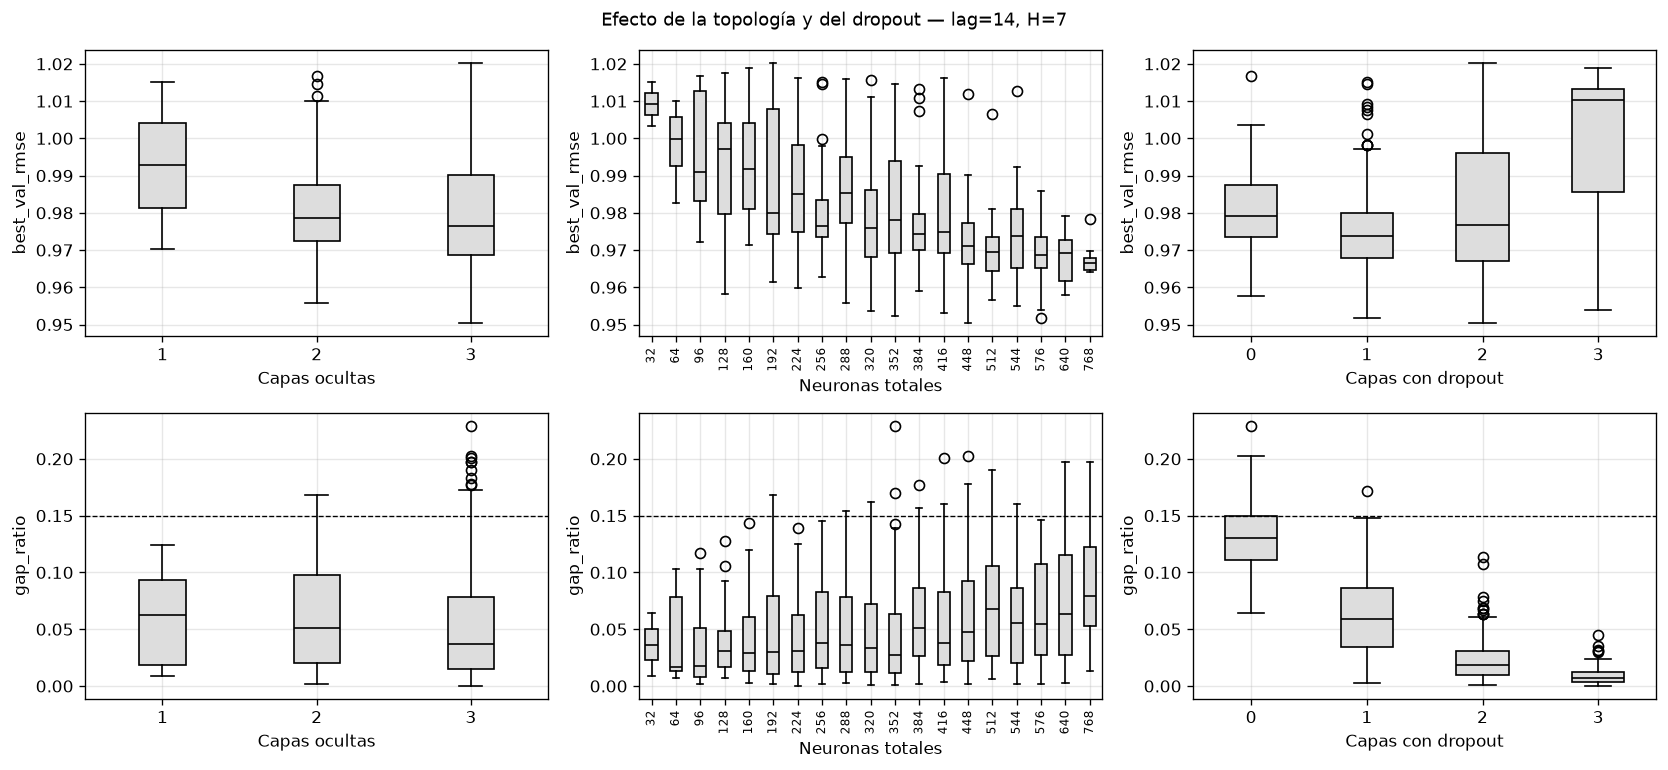

In [9]:
efectos = {
    'n_capas'       : 'Capas ocultas',
    'neuronas_total': 'Neuronas totales',
    'n_dropout'     : 'Capas con dropout',
}
for col, nombre in efectos.items():
    tabla = (df_res_demo.groupby(col)
             .agg(candidatos=('best_val_rmse', 'size'),
                  val_rmse_media=('best_val_rmse', 'mean'),
                  val_rmse_min=('best_val_rmse', 'min'),
                  gap_ratio_media=('gap_ratio', 'mean'),
                  balanceados=('balanceado', 'sum'))
             .round(4))
    print(f'=== {nombre} ===')
    display(tabla)

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for j, (col, nombre) in enumerate(efectos.items()):
    niveles = sorted(df_res_demo[col].unique())
    for i, metrica in enumerate(['best_val_rmse', 'gap_ratio']):
        datos_box = [df_res_demo.loc[df_res_demo[col] == v, metrica] for v in niveles]
        axes[i, j].boxplot(datos_box, tick_labels=[str(v) for v in niveles],
                           patch_artist=True, boxprops=dict(facecolor='#dddddd'),
                           medianprops=dict(color='black'))
        axes[i, j].set_xlabel(nombre)
        axes[i, j].set_ylabel('best_val_rmse' if i == 0 else 'gap_ratio')
        if col == 'neuronas_total':
            axes[i, j].tick_params(axis='x', labelrotation=90, labelsize=7)
    axes[1, j].axhline(GAP_UMBRAL, color='black', ls='--', lw=0.8)
plt.suptitle(f'Efecto de la topología y del dropout — lag={LAG_DEMO}, H={HORIZON_DEMO}', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'arq_efectos_capas_ancho_dropout.png'), dpi=150, bbox_inches='tight')
plt.show()

**Interpretación.** Sobre los 584 candidatos se observan tres efectos. La profundidad mejora poco el error medio (0,9928 con una capa, 0,9814 con dos y 0,9806 con tres), aunque el mejor mínimo aparece con tres capas (0,9504). El ancho total tiene un efecto monótono: el `best_val_rmse` medio baja de 0,9951 con 128 neuronas o menos a 0,9704 con más de 512, mientras el `gap_ratio` medio sube de 0,038 a 0,070. El dropout, por su parte, reduce la brecha de forma sistemática, de 0,134 sin dropout a 0,010 con dropout en las tres capas, y 20 de los 21 candidatos que no superan el filtro `gap_ratio < 0,15` son redes sin dropout.

Lo anterior indica el compromiso clásico entre sesgo y varianza: más capacidad, en capas y en neuronas, permite ajustar mejor y reduce el error de validación, pero también abre la brecha con el entrenamiento, y el dropout la cierra (Srivastava et al., 2014). Sin embargo, el exceso de regularización tiene costo: con dropout en las tres capas el error medio sube a 1,0002, peor que sin dropout (0,9806), porque con una tasa de 0,5 en todas las capas la red pierde capacidad efectiva. El mejor equilibrio aparece con dropout en una o dos capas, con errores medios de 0,9750 y 0,9815 y brechas de 0,063 y 0,024.

Por lo anterior, conviene preferir redes anchas de tres capas con dropout en las capas intermedias o finales, que es justamente el patrón de las arquitecturas ganadoras, y dejar como mejora posible explorar tasas de dropout menores (0,2 o 0,3), como sugiere el enunciado, para recuperar capacidad sin perder el control del sobreajuste.

## 9. Mejor arquitectura por (lag × horizonte)

Una búsqueda exhaustiva en las 16 combinaciones exigiría 16 × 584 ≈ 9 300 entrenamientos (unas 6 horas en CPU, según el tiempo medido por candidato). El enunciado admite trabajar sobre una configuración representativa siempre que se justifique y se documente. Aquí se adopta una variante más exigente: los **10 mejores candidatos** de la búsqueda exhaustiva se reentrenan en **cada una** de las 16 combinaciones, con la misma partición temporal y el mismo criterio de selección. Así la mejor arquitectura puede cambiar con el lag y con el horizonte. Cada tabla se guarda en `results/architecture_search_lag{L}_h{H}.csv`, y el resumen en `results/best_architecture_summary.csv`.

In [10]:
top_k = rank_demo.head(TOP_K_REEVAL)
CANDIDATOS_TOP = list(zip(top_k['arquitectura'], top_k['dropout_mask']))
registrar(f'Inicio: re-evaluación del Top-{TOP_K_REEVAL} en las 16 combinaciones lag × horizonte')

summary_rows = []
for lag in LAGS_LIST:
    for H in HORIZONS_LIST:
        if (lag, H) == (LAG_DEMO, HORIZON_DEMO):
            rank = rank_demo
        else:
            datos, _ = preparar(lag, H)
            rank = ranking(buscar_mejor_arquitectura(datos, CANDIDATOS_TOP, f'lag={lag} H={H}'))
            guardar_tabla(rank, lag, H)
        best = rank.iloc[0]
        summary_rows.append({
            'lag': lag, 'horizonte': H,
            'arquitectura': str(best['arquitectura']),
            'dropout_mask': str(best['dropout_mask']),
            'best_val_rmse': round(best['best_val_rmse'], 4),
            'gap_ratio': round(best['gap_ratio'], 4),
            'holdout_rmse': round(best['holdout_rmse'], 4),
            'balanceado': bool(best['balanceado']),
        })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(os.path.join(RESULTS_DIR, 'best_architecture_summary.csv'), index=False)
registrar('Fin del cuaderno 2: results/best_architecture_summary.csv guardado')
display(summary_df)

[18:37:23] Inicio: re-evaluación del Top-10 en las 16 combinaciones lag × horizonte


[18:38:53] lag=7 H=7: 10/10 candidatos | 1.5 min | faltan ~0.0 min


[18:40:20] lag=7 H=14: 10/10 candidatos | 1.4 min | faltan ~0.0 min


[18:41:32] lag=7 H=21: 10/10 candidatos | 1.2 min | faltan ~0.0 min


[18:42:32] lag=7 H=28: 10/10 candidatos | 1.0 min | faltan ~0.0 min


[18:43:37] lag=14 H=14: 10/10 candidatos | 1.0 min | faltan ~0.0 min


... (8 outputs left out)

[18:54:46] lag=28 H=21: 10/10 candidatos | 1.3 min | faltan ~0.0 min


[18:55:55] lag=28 H=28: 10/10 candidatos | 1.1 min | faltan ~0.0 min


[18:55:58] Fin del cuaderno 2: results/best_architecture_summary.csv guardado


,lag,horizonte,arquitectura,dropout_mask,best_val_rmse,gap_ratio,holdout_rmse,balanceado
0,7,7,"(64, 256, 128)","(False, True, True)",0.9504,0.0297,0.9623,True
1,7,14,"(64, 128, 256)","(False, False, True)",0.9912,0.0657,0.9797,True
2,7,21,"(256, 32, 128)","(False, True, True)",1.0026,0.0213,0.9792,True
3,7,28,"(256, 32, 128)","(False, True, True)",1.0168,0.0274,0.9874,True
4,14,7,"(64, 256, 128)","(False, True, True)",0.9504,0.0479,0.9602,True
5,14,14,"(64, 128, 256)","(False, False, True)",0.9998,0.1328,0.9843,True
6,14,21,"(64, 128, 256)","(False, False, True)",1.0142,0.0855,0.9872,True
7,14,28,"(256, 32, 256)","(False, True, True)",1.0145,0.0517,0.9902,True
8,21,7,"(256, 32, 256)","(False, True, True)",0.9672,0.0853,0.9711,True
9,21,14,"(64, 256, 128)","(False, True, True)",1.0060,0.1076,0.9949,True


**Interpretación.** En las 16 combinaciones la mejor arquitectura cumple el filtro `gap_ratio < 0,15` y tiene tres capas ocultas, pero no es siempre la misma: aparecen cinco topologías, encabezadas por (64, 256, 128), elegida en 5 combinaciones, y (256, 32, 256), elegida en 4. Todas aplican dropout en la última capa oculta, y la máscara más frecuente es (False, True, True), presente en 12 de las 16.

Esto quiere decir que el problema no exige una topología muy específica: dentro del Top-10 varias arquitecturas logran errores casi iguales, y la elección en cada combinación depende de diferencias pequeñas. Lo que sí se mantiene es el patrón estructural, tres capas con la primera sin dropout y regularización en las siguientes, que coincide con el análisis de la sección 8.1.

Con base en esto, se propone usar en el cuaderno 3 la arquitectura elegida para cada combinación lag × horizonte, tal como queda en `results/best_architecture_summary.csv`, en lugar de una arquitectura única, para respetar el resultado de la búsqueda en cada configuración.

## 10. Análisis: ¿cambia la arquitectura óptima con el horizonte?

Una pregunta de interés es si la arquitectura óptima varía al aumentar el horizonte de predicción (7 → 14 → 21 → 28 días). La tabla siguiente compara el `best_val_rmse` promedio por horizonte para todos los tamaños de lag.

=== best_val_rmse (escala estandarizada) por lag × horizonte ===


horizonte,7,14,21,28
lag,,,,
7,0.9504,0.9912,1.0026,1.0168
14,0.9504,0.9998,1.0142,1.0145
21,0.9672,1.0060,1.0152,1.0219
28,0.9959,1.0065,1.0243,1.0260


=== Arquitectura elegida por lag × horizonte ===


horizonte,7,14,21,28
lag,,,,
7,"(64, 256, 128)","(64, 128, 256)","(256, 32, 128)","(256, 32, 128)"
14,"(64, 256, 128)","(64, 128, 256)","(64, 128, 256)","(256, 32, 256)"
21,"(256, 32, 256)","(64, 256, 128)","(256, 32, 256)","(256, 32, 256)"
28,"(256, 64, 256)","(64, 256, 128)","(64, 256, 128)","(256, 32, 128)"


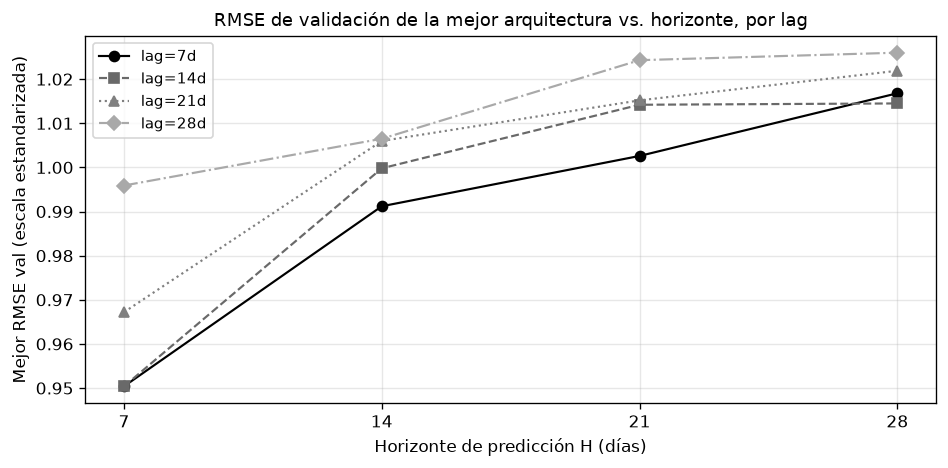

In [11]:
pivot = summary_df.pivot_table(index='lag', columns='horizonte', values='best_val_rmse', aggfunc='mean')
print('=== best_val_rmse (escala estandarizada) por lag × horizonte ===')
display(pivot.round(4))
print('=== Arquitectura elegida por lag × horizonte ===')
display(summary_df.pivot(index='lag', columns='horizonte', values='arquitectura'))

fig, ax = plt.subplots(figsize=(8, 4))
linestyles = ['-', '--', ':', '-.']
markers    = ['o', 's', '^', 'D']
for i, lag in enumerate(LAGS_LIST):
    sub = summary_df[summary_df.lag == lag].sort_values('horizonte')
    ax.plot(sub['horizonte'], sub['best_val_rmse'], ls=linestyles[i], marker=markers[i],
            color=['black', 'dimgray', 'gray', 'darkgray'][i], label=f'lag={lag}d', lw=1.3)
ax.set_xlabel('Horizonte de predicción H (días)')
ax.set_ylabel('Mejor RMSE val (escala estandarizada)')
ax.set_title('RMSE de validación de la mejor arquitectura vs. horizonte, por lag')
ax.set_xticks(HORIZONS_LIST)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'arq_rmse_vs_horizonte.png'), dpi=150)
plt.show()

**Interpretación.** Para todos los lags el `best_val_rmse` crece con el horizonte: con H = 7 está entre 0,9504 y 0,9959, y con H = 28 entre 1,0145 y 1,0260. Desde H = 14 los valores se acercan a 1 o lo superan, es decir, en esta partición los mejores modelos ya no mejoran a la media del entrenamiento. Por lag, 7 y 14 días quedan ligeramente por debajo de 21 y 28, con diferencias de 0,045 como máximo. La arquitectura elegida no cambia de forma monótona con el horizonte, aunque con H = 14 todas las elegidas empiezan con 64 neuronas y con H = 28 todas son del tipo (256, 32, ·), con un cuello de botella de 32 neuronas en la segunda capa.

En ese sentido, la información que el MLP extrae del propio pasado de la serie se concentra en los primeros días del horizonte y se diluye hacia los 28 días, un comportamiento esperable en una variable meteorológica diaria cuya dependencia temporal decae rápido. El patrón de arquitecturas por horizonte es sugerente, una red más compresiva para el horizonte más largo, pero como las diferencias dentro del Top-10 son pequeñas, no debe tomarse como una regla.

De ahí que se opte por evaluar todas las combinaciones con validación cruzada en el cuaderno 3 antes de elegir el lag del modelo final, y por interpretar los horizontes largos frente a referencias ingenuas, persistencia y media (cuaderno 4, sección 9), como recomiendan Hyndman y Athanasopoulos (2021) para juzgar si un pronóstico aporta información.

---

## 11. Conclusiones

1. La búsqueda sigue la metodología de `architectures_dropout.ipynb`: neuronas en {32, 64, 128, 256}, de una a tres capas, máscaras de dropout $2^n$, filtro `gap_ratio < 0,15` y selección por `best_val_rmse`, con el `holdout_rmse` solo como evidencia. Es exhaustiva (584 candidatos) en lag = 14 y H = 7, y el Top-10 se reevalúa en las otras 15 combinaciones.
2. La partición temporal de la búsqueda corrige una limitación de `timeseries-cv` 0.1.5, cuyos folds de Forward Chaining tienen una sola ventana de validación: se entrena con el fold del 80 % y se valida con las ventanas posteriores, con una purga que impide compartir objetivos entre ambos tramos.
3. Todas las arquitecturas elegidas tienen tres capas y dropout en la última capa oculta. Más ancho y más profundidad reducen el error de validación, el dropout controla la brecha y el exceso de dropout (tasa 0,5 en las tres capas) lleva a subajuste.
4. El filtro `gap_ratio < 0,15` discrimina poco en este problema, pues 563 de los 584 candidatos lo cumplen, porque EarlyStopping y dropout ya contienen el sobreajuste. En la práctica, la selección la determina el error de validación.
5. El error de validación de los mejores modelos está cerca de 1 en escala estandarizada y crece con el horizonte: el MLP extrae poca información del propio pasado de la serie, sobre todo más allá de 14 días. El cuaderno 4 cuantifica este resultado frente a referencias ingenuas.

## Referencias

- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3.ª ed.). OTexts.
- Prechelt, L. (1998). Early stopping — but when? En *Neural Networks: Tricks of the Trade* (pp. 55–69). Springer.
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research*, 15, 1929–1958.